# Polypus — demo

**QSTARS consortium · 14 October 2026**

Polypus is a distributed quantum computing library: a **Rust core** with a **Python API**, built to run the same code on a laptop, on an HPC cluster with many simulated QPUs, or on a real quantum processor.

This notebook presents the main features of Polypus, with a short example of each:

| # | Section | Contents |
|---|---|---|
| 0 | Setup | Installation, versions, per-machine auto-calibration |
| 1 | Circuits | Native Rust circuit builder, native drawing, OpenQASM 2.0 and 3 import/export, QIR export, Qiskit interop |
| 2 | Execution | Native Rust simulator and Qiskit Aer, reproducibility, exact statevectors, noise models |
| 3 | Multiple QPUs | Splitting shots across `n_qpus` and reading per-QPU results |
| 4 | HPC and real hardware | CUNQA (distributed QPUs over SLURM) and QMIO (CESGA's real QPU) |
| 5 | Variational training | QAOA for MaxCut with DE, PSO and QNG behind one `train()` call; native Rust cost functions |
| 6 | Quantum machine learning | Training and evaluating a VQC classifier |
| 7 | Performance | Gate fusion, GIL-free parallelism |
| 8 | Architecture and next steps | Rust workspace, pluggable backends, tutorials |

After the setup cell every section is self-contained, so any of them may be omitted.

## 0. Setup

Polypus is published on PyPI as `polypus-quantum` and imports as `polypus`. Prebuilt wheels install Qiskit and Qiskit Aer as dependencies; no compilation is required:

```bash
pip install polypus-quantum
```

This notebook uses only that package plus `matplotlib` for the plots.

In [ ]:
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import polypus
import qiskit
import qiskit_aer

print("polypus", polypus.__version__)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)
# Cores this process may use (respects CPU affinity on Linux, e.g. inside a batch job).
CPUS = (
    len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
)
print("CPU cores available:", CPUS)

# Plot style shared by every figure below.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY = "#898781"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "xtick.color": GREY,
        "ytick.color": GREY,
        "text.color": "#0b0b0b",
        "legend.frameon": False,
        "font.size": 11,
        "figure.dpi": 110,
    }
)

**Per-machine auto-calibration.** The native simulator switches its gate kernels from serial to multi-threaded above a qubit count that depends on the hardware. The first `import polypus` on a machine measures that crossover (well under a second) and caches it, keyed by CPU and thread count, so the nodes of a cluster sharing one `$HOME` keep separate entries. In a multi-process SLURM/MPI job only rank 0 calibrates. It can also be run explicitly:

In [ ]:
calibration = polypus.calibrate_parallel_threshold()
print(
    f"Multi-threaded kernels from {calibration['threshold']} qubits on, with {calibration['num_threads']} threads"
)

## 1. Circuits

`polypus.Circuit` is a circuit builder implemented in pure Rust (crate `polypus-circuit`). Gates chain fluently, and it covers the standard `qelib1.inc` gate set.

In [ ]:
ghz = polypus.Circuit(3).h(0).cx(0, 1).cx(1, 2).measure_all()

print(
    ghz.num_qubits,
    "qubits |",
    ghz.num_clbits,
    "clbits |",
    ghz.num_params,
    "free parameters",
)
print(ghz.to_qasm2())

**Interoperability.** OpenQASM 2.0 import is the inverse of export (round trips are byte-identical), and it also accepts the format Qiskit produces, so existing Qiskit circuits can be imported directly. Circuits can also be exported to **QIR** (LLVM IR text, or bitcode with `to_qir_bitcode()`).

In [ ]:
from qiskit import QuantumCircuit, qasm2

# Round trip: export -> import -> export gives the same text.
print(
    "round trip identical:",
    polypus.Circuit.from_qasm2(ghz.to_qasm2()).to_qasm2() == ghz.to_qasm2(),
)

# A circuit written in Qiskit, brought into Polypus through OpenQASM.
qk_ghz = QuantumCircuit(3)
qk_ghz.h(0)
qk_ghz.cx(0, 1)
qk_ghz.cx(1, 2)
qk_ghz.measure_all()
from_qiskit = polypus.Circuit.from_qasm2(qasm2.dumps(qk_ghz))
print("imported from Qiskit:", from_qiskit.num_qubits, "qubits")

# QIR export (first lines).
print()
print("\n".join(ghz.to_qir().splitlines()[:10]))

**Drawing.** A circuit draws itself, natively and without Qiskit or matplotlib: `print(circuit)` gives a text drawing, `circuit.draw("svg")` an SVG document, and a circuit on the last line of a notebook cell is displayed as that SVG:

In [ ]:
ghz

**Parameterized circuits and templates.** `polypus.Param(i)` marks a trainable parameter; values are bound later, in Rust and without holding the GIL. `polypus.circuits.templates` provides predefined circuits, for example the QFT:

In [ ]:
ansatz = polypus.Circuit(2).ry(0, polypus.Param(0)).ry(1, polypus.Param(1)).cx(0, 1)
print("ansatz free parameters:", ansatz.num_params)

qft4 = polypus.circuits.templates.qft(4)
print(qft4.to_qasm2())

**OpenQASM 3 and angle expressions.** Unlike OpenQASM 2.0, the OpenQASM 3 export keeps free parameters, as `input float[64]` declarations, and an angle can be an expression of the parameters, such as `2 * Param(0)` or `polypus.sin(Param(1))`. Import is the inverse of export, byte for byte:

In [ ]:
from polypus import Param

layer = polypus.Circuit(2).h(0).h(1).rzz(0, 1, 2 * Param(0)).rx(0, Param(1))
qasm3_text = layer.to_qasm3()
print(qasm3_text)
print(
    "round trip identical:",
    polypus.Circuit.from_qasm3(qasm3_text).to_qasm3() == qasm3_text,
)

## 2. Execution

One function, `polypus.run_quantum_circuit`, runs a circuit on any of the supported infrastructures. Two arguments determine where:

- `infrastructure`: `"local"` (this machine), `"cunqa"` (CESGA's distributed QPUs) or `"qmio"` (CESGA's real QPU).
- `backend`, for local runs: `"polypus"` (the native Rust statevector simulator) or `"aer"` (Qiskit Aer, the default).

In [ ]:
for backend in ("polypus", "aer"):
    result = polypus.run_quantum_circuit(
        ghz, shots=1000, infrastructure="local", backend=backend, seed=42
    )
    print(f"{backend:>8}: {result.merged_counts}")

**Three input formats.** The same call accepts a native `polypus.Circuit`, a Qiskit `QuantumCircuit` or an OpenQASM 2.0 string:

In [ ]:
inputs = {
    "polypus.Circuit": ghz,
    "qiskit.QuantumCircuit": qk_ghz,
    "OpenQASM 2.0 string": qasm2.dumps(qk_ghz),
}
for name, circuit in inputs.items():
    result = polypus.run_quantum_circuit(
        circuit, shots=1000, infrastructure="local", seed=7
    )
    print(f"{name:>22}: {result.merged_counts}")

**Reproducibility and run manifest.** With a `seed`, shot noise is reproduced exactly on every simulated backend (native, Aer and CUNQA's simulated QPUs). Without one, a fresh seed is drawn from OS entropy and reported back, so any run can be replayed. Each `RunResult` carries a manifest for logging:

In [ ]:
first = polypus.run_quantum_circuit(
    ghz, shots=1000, infrastructure="local", backend="polypus"
)
replay = polypus.run_quantum_circuit(
    ghz, shots=1000, infrastructure="local", backend="polypus", seed=first.seed
)

print(
    "same counts when replayed with the reported seed:",
    first.merged_counts == replay.merged_counts,
)
print(first)

**Exact statevectors.** `polypus.statevector` returns the full amplitude vector from the native simulator as a NumPy array, in the same qubit order as Qiskit, so the two can be compared directly:

In [ ]:
from qiskit.quantum_info import Statevector

ghz_state = polypus.Circuit(3).h(0).cx(0, 1).cx(1, 2)
amplitudes = polypus.statevector(ghz_state)
print(np.round(amplitudes, 3))

qk_state = QuantumCircuit(3)
qk_state.h(0)
qk_state.cx(0, 1)
qk_state.cx(1, 2)
print(
    "matches qiskit.quantum_info.Statevector:",
    np.allclose(amplitudes, Statevector(qk_state).data),
)

# Parameterized circuits take their values at call time.
print(
    "ansatz at (pi/2, 0):", np.round(polypus.statevector(ansatz, [math.pi / 2, 0.0]), 3)
)

**Noise models.** Any Qiskit Aer `NoiseModel` can be passed to the local Aer backend:

In [ ]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

noise = NoiseModel()
noise.add_all_qubit_quantum_error(depolarizing_error(0.05, 1), ["h"])
noise.add_all_qubit_quantum_error(depolarizing_error(0.08, 2), ["cx"])

ideal = polypus.run_quantum_circuit(
    ghz, shots=4000, infrastructure="local", backend="aer", seed=3
)
noisy = polypus.run_quantum_circuit(
    ghz, shots=4000, infrastructure="local", backend="aer", noise_model=noise, seed=3
)

outcomes = [format(i, "03b") for i in range(8)]
x = np.arange(len(outcomes))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(
    x - 0.2,
    [ideal.merged_counts.get(o, 0) for o in outcomes],
    0.38,
    color=BLUE,
    label="ideal",
)
ax.bar(
    x + 0.2,
    [noisy.merged_counts.get(o, 0) for o in outcomes],
    0.38,
    color=ORANGE,
    label="depolarizing noise",
)
ax.set_xticks(x, outcomes)
ax.set_xlabel("measured bitstring")
ax.set_ylabel("counts (4000 shots)")
ax.set_title("GHZ state on Aer: ideal vs noisy", loc="left")
ax.legend(loc="upper center")
plt.show()

## 3. Multiple QPUs

`n_qpus=N` splits the shots across N QPUs. The result keeps both views:

- `result.counts`: a list with one counts dict per QPU, in the order the shots were split.
- `result.merged_counts`: their sum, the circuit's counts over every shot.

The result has the same shape for any `n_qpus`, so code written for one QPU does not change when scaling out.

In [ ]:
multi = polypus.run_quantum_circuit(
    ghz, shots=4000, infrastructure="local", backend="polypus", n_qpus=4, seed=11
)

for qpu, counts in enumerate(multi.counts):
    print(f"QPU {qpu}: {sum(counts.values())} shots -> {counts}")
print(f"merged : {sum(multi.merged_counts.values())} shots -> {multi.merged_counts}")

fig, ax = plt.subplots(figsize=(7, 2.8))
labels = [f"QPU {i}" for i in range(len(multi.counts))]
zeros = [c.get("000", 0) for c in multi.counts]
ones = [c.get("111", 0) for c in multi.counts]
ax.barh(labels, zeros, color=BLUE, label="000", edgecolor="#fcfcfb", linewidth=2)
ax.barh(
    labels,
    ones,
    left=zeros,
    color=ORANGE,
    label="111",
    edgecolor="#fcfcfb",
    linewidth=2,
)
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("shots")
ax.set_title("4000 shots split across 4 QPUs", loc="left")
ax.legend(ncols=2, loc="lower right", bbox_to_anchor=(1, 1))
plt.show()

With `infrastructure="local"` the QPUs are replicas on a single machine, so this example illustrates the mechanism and the result format, not a speed-up. Reductions in wall-clock time are obtained with CUNQA (next section), where each QPU is its own process on nodes allocated through SLURM. The same `n_qpus` also spreads the population of an optimizer (section 5) and the samples of a QML dataset (section 6) across QPUs.

## 4. HPC and real hardware

**CUNQA** is CESGA's platform for distributed simulated QPUs on SLURM. Moving the code above to the cluster changes only `infrastructure`, plus three optional arguments that size the SLURM allocation:

```python
result = polypus.run_quantum_circuit(
    ghz,
    shots=100_000,
    infrastructure="cunqa",
    n_qpus=10,  # QPUs deployed by CUNQA
    nodes=2,  # SLURM nodes
    cores_per_qpu=4,  # CPU cores per QPU
    walltime="02:00:00",  # SLURM walltime of the QPUs, HH:MM:SS
)
```

The `cunqa` Python package is installed separately (see the README). It is not installed in this demo environment, so this cell is shown without being run. The QPUs are released when the walltime runs out; when a training on CUNQA is projected to outlast it, Polypus logs a warning after the first generation. CUNQA's QPUs run Aer, so a non-Aer `backend` or a `noise_model` is rejected instead of being ignored.

**QMIO** is CESGA's real quantum computer. Polypus communicates with it through a pure-Rust ZeroMQ client that does not hold the GIL, using `infrastructure="qmio"`. That backend is compiled only into source builds with `--features qmio`, not into the PyPI wheel. It has no default endpoint: the address is read from `ZMQ_SERVER` or passed as `options={"endpoint": ...}`. It runs native circuits and OpenQASM 2.0 strings, not Qiskit `QuantumCircuit` objects, because it serializes them without the Python interpreter.

Invalid arguments are rejected before anything reaches SLURM or the hardware, so errors are reported immediately, even on a laptop:

In [ ]:
attempts = {
    "cunqa with nodes=0": dict(infrastructure="cunqa", nodes=0),
    "cunqa, D-HH:MM:SS walltime": dict(infrastructure="cunqa", walltime="2-00:00:00"),
    "cunqa with backend=polypus": dict(infrastructure="cunqa", backend="polypus"),
    "qmio from the PyPI wheel": dict(infrastructure="qmio"),
    "qmio with a seed": dict(infrastructure="qmio", seed=42),
}
for label, kwargs in attempts.items():
    try:
        polypus.run_quantum_circuit(ghz, shots=1000, **kwargs)
    except ValueError as error:
        print(f"{label:>26}: ValueError: {error}")

Errors raised while running have their own hierarchy, which lets callers catch every backend failure, or only the ones from a specific infrastructure:

In [ ]:
for name in (
    "BackendError",
    "CunqaError",
    "QmioError",
    "NativeCircuitError",
    "EvaluationError",
):
    chain = [
        cls.__name__
        for cls in getattr(polypus, name).__mro__
        if cls.__module__ != "builtins"
    ]
    print(" -> ".join(chain))

## 5. Variational training: QAOA for MaxCut

`polypus.train` optimizes any parameterized circuit. The optimizer is an argument: **Differential Evolution** (`DE`), **Particle Swarm Optimization** (`PSO`) or **Quantum Natural Gradient** (`QNG`), all implemented in Rust. Each candidate's circuit is bound and evaluated in Rust, and the population is spread across `n_qpus`.

The problem: split the nodes of this graph into two groups so that as many edges as possible cross between them.

In [ ]:
import itertools

N_NODES = 6
EDGES = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0), (0, 3), (1, 4)]
LAYERS = 2


def cut_size(bitstring):
    bits = bitstring[::-1]  # Qiskit order: qubit 0 is the right-most bit
    return sum(bits[i] != bits[j] for i, j in EDGES)


def draw_graph(ax, bitstring=None, title=""):
    angle = np.linspace(0, 2 * np.pi, N_NODES, endpoint=False) + np.pi / 2
    pos = np.c_[np.cos(angle), np.sin(angle)]
    bits = bitstring[::-1] if bitstring else "0" * N_NODES
    for i, j in EDGES:
        crossing = bitstring is not None and bits[i] != bits[j]
        ax.plot(
            *pos[[i, j]].T,
            color=ORANGE if crossing else "#c3c2b7",
            lw=2.5 if crossing else 1.5,
            zorder=1,
        )
    colors = (
        [BLUE if b == "0" else AQUA for b in bits] if bitstring else [GREY] * N_NODES
    )
    ax.scatter(*pos.T, s=600, c=colors, edgecolors="#fcfcfb", linewidths=2, zorder=2)
    for k, (px, py) in enumerate(pos):
        ax.text(
            px,
            py,
            str(k),
            ha="center",
            va="center",
            color="white",
            fontweight="bold",
            zorder=3,
        )
    ax.set_title(title, loc="left")
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect("equal")
    ax.axis("off")


MAX_CUT = max(cut_size("".join(b)) for b in itertools.product("01", repeat=N_NODES))
fig, ax = plt.subplots(figsize=(3.2, 3.2))
draw_graph(ax, title=f"{N_NODES} nodes, {len(EDGES)} edges")
plt.show()
print("optimal cut (brute force):", MAX_CUT, "edges")

The QAOA circuit, built with the native builder. Parameters alternate per layer: `Param(2k)` is the cost angle γₖ and `Param(2k+1)` the mixer angle βₖ. The same function also builds the circuit up to a given parameter, which QNG needs below.

In [ ]:
def qaoa_circuit(n_params=2 * LAYERS, values=None, measure=True):
    """QAOA up to (not including) parameter index n_params; values=None leaves them free."""
    angle = (lambda k: polypus.Param(k)) if values is None else (lambda k: values[k])
    circuit = polypus.Circuit(N_NODES)
    for q in range(N_NODES):
        circuit = circuit.h(q)
    for k in range(n_params):
        if k % 2 == 0:  # cost layer: exp(-i γ/2 Z_i Z_j) on every edge
            for i, j in EDGES:
                circuit = circuit.rzz(i, j, angle(k))
        else:  # mixer layer: RX(β) on every qubit
            for q in range(N_NODES):
                circuit = circuit.rx(q, angle(k))
    return circuit.measure_all() if measure else circuit


qaoa = qaoa_circuit()
print("trainable parameters:", qaoa.num_params)

**Cost functions: Python or native Rust.** The objective can be any Python function of a bitstring. For diagonal costs such as QUBO or Ising there are native observables (`polypus.Qubo`, `polypus.Ising`) evaluated in Rust without the GIL. MaxCut in Ising form is `cut = Σ₍ᵢⱼ₎ (1 − zᵢzⱼ)/2`. Optimizers **maximize**, and with the same seed both versions find exactly the same solution:

In [ ]:
maxcut_ising = polypus.Ising(
    N_NODES, couplings=[(i, j, -0.5) for i, j in EDGES], constant=len(EDGES) / 2
)

COMMON = dict(
    shots=1024,
    n_qpus=4,
    dimensions=2 * LAYERS,
    infrastructure="local",
    nodes=1,
    cores_per_qpu=1,
    seed=1,
)

for label, cost in (("Python function", cut_size), ("polypus.Ising", maxcut_ising)):
    result = polypus.train(
        qaoa,
        polypus.DE(generations=40, population_size=20),
        expectation_function=cost,
        id="maxcut",
        **COMMON,
    )
    print(
        f"{label:>15}: mean cut {result.best_fitness:.3f}, parameters {np.round(result.best_params, 3)}"
    )

**Choice of optimizer.** Switching optimizer only requires changing one argument. QNG also needs the diagonal of the quantum Fisher information. Here it is computed exactly from the variance of each layer's generator, using `polypus.statevector` on the circuit prefix:

In [ ]:
basis = (
    np.arange(2**N_NODES)[:, None] >> np.arange(N_NODES)
) & 1  # bit q of each basis state
spins = 1 - 2 * basis
COST_GENERATOR = (
    sum(spins[:, i] * spins[:, j] for i, j in EDGES) / 2
)  # generator of a γ layer
MIXER_GENERATOR = spins.sum(axis=1) / 2  # generator of a β layer, read in the X basis


def qaoa_variance(theta, a):
    """Variance of parameter a's generator in the state prepared by parameters 0..a-1."""
    prefix = qaoa_circuit(n_params=a, measure=False)
    if a % 2 == 1:  # next parameter is a β: rotate into the X basis
        for q in range(N_NODES):
            prefix = prefix.h(q)
    probs = np.abs(polypus.statevector(prefix, list(theta[:a]) or None)) ** 2
    g = COST_GENERATOR if a % 2 == 0 else MIXER_GENERATOR
    return float(probs @ g**2 - (probs @ g) ** 2)


optimizers = {
    "DE": polypus.DE(generations=40, population_size=20),
    "PSO": polypus.PSO(generations=40, population_size=20, bounds=(0.0, math.pi)),
    "QNG": polypus.QNG(
        qaoa_variance, max_iters=40, bounds=(0.0, math.pi), learning_rate=0.3
    ),
}
results = {}
for name, optimizer in optimizers.items():
    start = time.perf_counter()
    results[name] = polypus.train(
        qaoa,
        optimizer,
        expectation_function=maxcut_ising,
        id=f"maxcut_{name}",
        **COMMON,
    )
    r = results[name]
    print(
        f"{name:>3}: mean cut {r.best_fitness:.3f} / {MAX_CUT}  "
        f"iterations {r.iterations_run:>2}  converged {r.converged!s:>5}  {time.perf_counter() - start:.2f} s"
    )

**Interpreting the solution.** The circuit is run with the best parameters found, and the resulting distribution of cut sizes is compared with random guessing (a uniformly random bitstring). The most frequent bitstring is the proposed partition:

In [ ]:
best_name = max(results, key=lambda name: results[name].best_fitness)
best = results[best_name]
final = polypus.run_quantum_circuit(
    qaoa_circuit(values=best.best_params),
    shots=8192,
    infrastructure="local",
    backend="polypus",
    seed=5,
)

sizes = np.arange(len(EDGES) + 1)
qaoa_dist = np.zeros(len(sizes))
for bits, n in final.merged_counts.items():
    qaoa_dist[cut_size(bits)] += n / 8192
random_dist = np.zeros(len(sizes))
for bits in itertools.product("01", repeat=N_NODES):
    random_dist[cut_size("".join(bits))] += 1 / 2**N_NODES
top = max(final.merged_counts, key=final.merged_counts.get)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2.2, 1]}
)
ax1.bar(sizes - 0.2, random_dist, 0.38, color=GREY, label="random bitstring")
ax1.bar(sizes + 0.2, qaoa_dist, 0.38, color=BLUE, label=f"QAOA ({best_name})")
ax1.set_xticks(sizes)
ax1.set_xlabel("cut size (edges)")
ax1.set_ylabel("probability")
ax1.set_title(
    f"P(optimal cut = {MAX_CUT}): random {random_dist[MAX_CUT]:.0%}, QAOA {qaoa_dist[MAX_CUT]:.0%}",
    loc="left",
)
ax1.legend()
draw_graph(ax2, top, title=f"most frequent: {top}, cut {cut_size(top)}")
plt.show()

## 6. Quantum machine learning: a VQC classifier

`polypus.qml.train` trains a data-encoding circuit: a **feature map** encodes each sample, an **ansatz** holds the trainable weights. With `y_train`, each sample is scored against its own label. `polypus.qml.predict` then runs every test sample in a single scheduled batch.

The dataset: two noisy 2-D clusters, one per class.

In [ ]:
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes

rng = np.random.default_rng(7)
n_per_class = 20
X = np.vstack(
    [rng.normal(0.9, 0.35, (n_per_class, 2)), rng.normal(2.2, 0.35, (n_per_class, 2))]
).clip(0, np.pi)
y = np.repeat([0, 1], n_per_class)
order = rng.permutation(len(y))
X, y = X[order], y[order]
X_train, y_train, X_test, y_test = X[:28], y[:28], X[28:], y[28:]

# Angle encoding (one RY per feature) followed by a hardware-efficient ansatz.
x = ParameterVector("x", 2)
feature_map = QuantumCircuit(2)
for q in range(2):
    feature_map.ry(x[q], q)
vqc_ansatz = real_amplitudes(num_qubits=2, reps=1)


def predicted_class(bitstring):
    return int(bitstring[-1])  # read qubit 0 (the right-most bit)


def correct(bitstring, label):
    # Averaged over the shots, this is the expected accuracy.
    return float(predicted_class(bitstring) == label)


start = time.perf_counter()
vqc = polypus.qml.train(
    feature_map,
    vqc_ansatz,
    X_train,
    polypus.DE(generations=30, population_size=12),
    y_train=y_train,
    shots=512,
    n_qpus=4,
    dimensions=len(vqc_ansatz.parameters),
    expectation_function=correct,
    infrastructure="local",
    nodes=1,
    cores_per_qpu=1,
    id="vqc",
    seed=42,
)
print(
    f"trained in {time.perf_counter() - start:.2f} s, expected training accuracy {vqc.best_fitness:.2f}"
)

**Evaluation.** One `predict` call for the held-out samples, and another one for a 20 × 20 grid that draws the learned decision regions (400 circuits in one batch):

In [ ]:
def majority_class(counts):
    votes = np.zeros(2)
    for bits, n in counts.items():
        votes[predicted_class(bits)] += n
    return int(votes.argmax())


test_run = polypus.qml.predict(
    feature_map,
    vqc_ansatz,
    X_test,
    vqc.best_params,
    shots=512,
    infrastructure="local",
    seed=7,
)
test_pred = np.array([majority_class(c) for c in test_run.counts])
print(
    f"test accuracy: {np.mean(test_pred == y_test):.2f} on {len(y_test)} held-out samples"
)

grid = np.linspace(0, np.pi, 20)
gx, gy = np.meshgrid(grid, grid)
grid_run = polypus.qml.predict(
    feature_map,
    vqc_ansatz,
    np.c_[gx.ravel(), gy.ravel()],
    vqc.best_params,
    shots=256,
    infrastructure="local",
    seed=7,
)
regions = np.array([majority_class(c) for c in grid_run.counts]).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.contourf(gx, gy, regions, levels=[-0.5, 0.5, 1.5], colors=["#cde2fb", "#fbd9c9"])
for cls, color, marker in ((0, BLUE, "o"), (1, ORANGE, "^")):
    ax.scatter(
        *X_train[y_train == cls].T,
        c=color,
        marker=marker,
        s=45,
        edgecolors="#fcfcfb",
        label=f"class {cls} (train)",
    )
    ax.scatter(
        *X_test[y_test == cls].T,
        c="none",
        marker=marker,
        s=60,
        edgecolors=color,
        linewidths=1.8,
        label=f"class {cls} (test)",
    )
ax.set_xlabel("feature 0")
ax.set_ylabel("feature 1")
ax.grid(False)
ax.set_title("Learned decision regions", loc="left")
ax.legend(fontsize=8, loc="upper left")
plt.show()

**Other losses.** A per-shot score (as above) gives the expected accuracy. For losses that are not linear in the outcome probabilities, such as the log-likelihood (cross-entropy), `polypus.SampleCost` scores each sample's whole counts dict instead. `polypus.CachedCost` memoizes a pure cost function across generations.

In [ ]:
def log_likelihood(counts, label):
    hits = sum(n for bits, n in counts.items() if predicted_class(bits) == label)
    # Clip before the log: every score must be finite.
    return math.log(max(hits / sum(counts.values()), 1e-6))


vqc_ll = polypus.qml.train(
    feature_map,
    vqc_ansatz,
    X_train,
    polypus.DE(generations=30, population_size=12),
    y_train=y_train,
    shots=512,
    n_qpus=4,
    dimensions=len(vqc_ansatz.parameters),
    expectation_function=polypus.SampleCost(log_likelihood),
    infrastructure="local",
    nodes=1,
    cores_per_qpu=1,
    id="vqc_ll",
    seed=42,
)
ll_run = polypus.qml.predict(
    feature_map,
    vqc_ansatz,
    X_test,
    vqc_ll.best_params,
    shots=512,
    infrastructure="local",
    seed=7,
)
print(
    f"mean log-likelihood {vqc_ll.best_fitness:.3f}, test accuracy {np.mean([majority_class(c) for c in ll_run.counts] == y_test):.2f}"
)

## 7. Performance

**Gate fusion.** The native simulator merges runs of consecutive gates into fewer, larger matrix applications. It is on by default; `fusion=False` turns it off to compare. The circuit is a hardware-efficient ansatz on 22 qubits (8 layers of RZ·RY·RZ plus a CX chain):

In [ ]:
def hea(n_qubits, layers):
    circuit = polypus.Circuit(n_qubits)
    for layer in range(layers):
        for q in range(n_qubits):
            a = 0.1 * (q + 1) + 0.3 * layer
            circuit = circuit.rz(q, a).ry(q, a / 2).rz(q, a / 3)
        for q in range(n_qubits - 1):
            circuit = circuit.cx(q, q + 1)
    return circuit


def best_time(fn, repeats=3):
    best, out = float("inf"), None
    for _ in range(repeats):
        start = time.perf_counter()
        out = fn()
        best = min(best, time.perf_counter() - start)
    return best, out


hea_22 = hea(22, 8)
t_off, sv_off = best_time(lambda: polypus.statevector(hea_22, fusion=False))
t_on, sv_on = best_time(lambda: polypus.statevector(hea_22, fusion=True))
print(
    f"fusion off {t_off:.3f} s | fusion on {t_on:.3f} s | {t_off / t_on:.2f}x faster | same result: {np.allclose(sv_off, sv_on)}"
)

**GIL-free execution.** The simulator is implemented in Rust and releases Python's GIL while it computes. Simulations launched from Python threads therefore run genuinely in parallel, each on its own core; with pure-Python code the GIL would force them to run one at a time. The Rust core relies on the same property to evaluate an optimizer's candidates in parallel. Here, 64 independent 14-qubit simulations (each below the multi-threading threshold from section 0, so one core each) are spread over a growing thread pool, up to the cores available:

In [ ]:
from concurrent.futures import ThreadPoolExecutor

layered = polypus.Circuit(14)
for _ in range(40):
    for q in range(14):
        layered = layered.ry(q, polypus.Param(q))
    for q in range(13):
        layered = layered.cx(q, q + 1)
batch = [[0.01 * k + 0.1 * q for q in range(14)] for k in range(64)]

polypus.statevector(layered, batch[0])  # warm-up
start = time.perf_counter()
for params in batch:
    polypus.statevector(layered, params)
sequential = time.perf_counter() - start

threads = [t for t in (1, 2, 4, 8, 16, 32) if t <= CPUS]
speedups = []
for n_threads in threads:
    with ThreadPoolExecutor(n_threads) as pool:
        start = time.perf_counter()
        list(pool.map(lambda p: polypus.statevector(layered, p), batch))
        speedups.append(sequential / (time.perf_counter() - start))
    print(
        f"{n_threads:>2} {'thread' if n_threads == 1 else 'threads'}: {speedups[-1]:.1f}x"
    )

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(threads, threads, color=GREY, lw=1.5, ls="--", label="ideal")
ax.plot(threads, speedups, color=BLUE, lw=2, marker="o", markersize=8, label="measured")
ax.set_xscale("log", base=2)
ax.set_yscale("log", base=2)
ax.set_xticks(threads, threads)
ax.set_yticks(threads, threads)
ax.set_xlabel("Python threads")
ax.set_ylabel("speed-up vs sequential")
ax.set_title("64 statevectors from Python threads", loc="left")
ax.legend()
plt.show()

## 8. Architecture and next steps

Polypus is a Cargo workspace of independent crates. Only three of them link against Python (via PyO3); the pure-Rust ones can be used standalone from any Rust project:

| Crate | Role |
|---|---|
| `polypus-circuit` | Circuit IR, OpenQASM 2.0 and 3 import/export, QIR export, text and SVG drawing |
| `polypus-sim` | Native statevector simulator (gate fusion, auto-calibrated parallel kernels) |
| `polypus-optimizers` | DE, PSO, QNG |
| `polypus-observable` | Native cost observables (QUBO / Ising) |
| `polypus-physics` | Monte Carlo transport and Pauli-sum Hamiltonians |
| `polypus-backend`, `polypus-subprocess-backend`, `polypus-backend-conformance` | The `QuantumBackend` trait, the subprocess bridge for external SDKs, and the conformance test suite |
| `polypus-infrastructure` | Backends: native, Aer, CUNQA, QMIO |
| `polypus-orchestration`, `polypus-evaluation` | Scheduling, optimizer dispatch, training oracles |
| `polypus` | The Python extension (`import polypus`) |

**Integrating new backends.** A new backend implements one small trait from `polypus-backend`, which has no PyO3, Qiskit or Python dependency. It is then registered by name, and every algorithm above runs on it unchanged. Python SDKs can be connected through a subprocess bridge, and a conformance test suite checks a new backend against the contract. Details are in `docs/backends.md`.

**Further resources:**

- Documentation: <https://bahia-software.github.io/polypus/>
- Source code: <https://github.com/Bahia-Software/polypus>
- Step-by-step tutorials, in English and Spanish ([en](https://github.com/Bahia-Software/polypus/tree/main/tutorials/en) · [es](https://github.com/Bahia-Software/polypus/tree/main/tutorials/es)):

| Tutorial | Topic |
|---|---|
| `00_welcome`, `00a`, `00b` | Welcome, Python basics, quantum intuition |
| `01_first_circuit` | First circuit, end to end |
| `02a_gates_and_circuits`, `02b_qiskit_qasm_interop` | Gates, building circuits, Qiskit and QASM interop |
| `03a_local_execution`, `03b_scaling_cunqa_qmio` | Local execution; scaling to CUNQA and QMIO |
| `04a_teleportation`, `04b_qft` | Teleportation, quantum Fourier transform |
| `05a_deutsch_jozsa`, `05b_grover` | Deutsch–Jozsa, Grover search |
| `06a_variational_training`, `06b_pso_qng_optimizers` | Variational training; PSO and QNG |
| `from_qiskit_to_polypus` | Migration guide for Qiskit users |

---

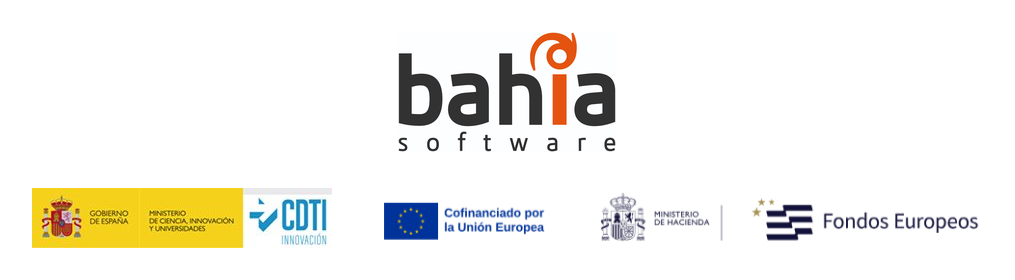